# How close is the NTK prediction to the local score theory?

Side-by-side samples from three score functions, for each trained backbone:

1. **the trained network** &mdash; the actual ResNet / UNet / DiT denoiser;
2. **its NTK prediction** &mdash; what NTK theory says a network of this architecture converges to under gradient flow from initialization, fit as a per-noise-level kernel ridge regression (`scripts/fit_ntk_score.py`);
3. **a local score machine** &mdash; bbELS or LS, the analytic equivariant-local-score prediction from the paper (`src/utils/idealscore.py`).

All three are driven through the **same** reverse loop (`ScheduledScoreMachine`) from the **same** seed noise, so a difference between columns is a difference in the score and not in the sampler.

## What to keep in mind when reading this

- **The NTK expansion point is a re-draw, not the original init.** None of the trained runs kept an epoch-0 checkpoint, so `theta0` is a fresh seeded draw from the same architecture's init ensemble. NTK theory only needs *an* init from that ensemble, but it is not literally the init these weights came from.
- **The NTK regression is fit at one pixel.** Following the convention in `scripts/resnet_patch_ntk.py`, the readout is the network output at a single pixel (one row per colour channel). The fitted `dtheta` then predicts at *every* pixel, because the directional derivative is taken on the full network output &mdash; but only the centre pixel was constrained during the fit.
- **The data budgets differ.** The local score machines stream ~10<sup>4</sup> images; the NTK fit is capped by the cost of per-sample parameter gradients. The `matched` row re-runs the local score machine on *exactly* the images the NTK regression saw, which is the like-for-like comparison.
- **One regression per noise level.** A separate kernel ridge problem is solved at each of the 20 reverse steps, rather than one joint fit across `t`. This mirrors how the local score machines take a per-timestep scale `k`, but it is not the same object as a single network trained jointly over all `t`.

A companion notebook, [`ntk_why_it_fails.ipynb`](./ntk_why_it_fails.ipynb), takes the gap this notebook measures and tests four explanations for it.


In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path(os.path.abspath("")).resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.utils.idealscore import denormalize

RESULTS = ROOT / "results" / "ntk_score"
print(ROOT)

/scratch/users/hshunt/convolutional_diffusion


In [2]:
# Artifacts come from scripts/slurm_ntk_vs_els.sh; the notebook only loads and plots,
# per the project convention of keeping expensive computation out of notebooks.
#
# Files are tagged by readout. The "_random" fits are the ones to read; the "_center"
# fits are kept as the contrast that shows why the readout placement matters, and are
# ordered last so they never lead.
def readout_of(art, path):
    tagged = path.stem.rsplit("_", 1)[-1]
    return art.get("ntk_readout", tagged if tagged in ("center", "random") else "center")

artifact_paths = sorted(RESULTS.glob("comparison_*.pt"))
if not artifact_paths:
    raise FileNotFoundError(
        f"No comparison artifacts in {RESULTS}. Run:\n"
        "    sbatch scripts/slurm_ntk_vs_els.sh                          # ResNet + bbELS\n"
        "    ARCH=UNet SCORE_TYPE=LS sbatch scripts/slurm_ntk_vs_els.sh  # UNet + LS"
    )

loaded = []
for path in artifact_paths:
    art = torch.load(path, map_location="cpu", weights_only=False)
    art["_readout"] = readout_of(art, path)
    loaded.append((path.stem.replace("comparison_", ""), art))
loaded.sort(key=lambda kv: (kv[1]["_readout"] != "random", kv[0]))
artifacts = dict(loaded)

for name, art in artifacts.items():
    print(f"{name:42s} {art['network_label']:8s} vs {art['score_module_type']:6s}  "
          f"readout={art['_readout']:6s}  n_samples={art['samples']['network'].shape[0]}  "
          f"NTK n_train={art['ntk_n_train']}")

celeba_DiT_LS_N1024_random                 DiT      vs LS      readout=random  n_samples=8  NTK n_train=1024
celeba_ResNet_bbELS_N1024_random           ResNet   vs bbELS   readout=random  n_samples=8  NTK n_train=1024
celeba_UNet_LS_N1024_random                UNet     vs LS      readout=random  n_samples=8  NTK n_train=1024
celeba_DiT_LS_N1024_center                 DiT      vs LS      readout=center  n_samples=8  NTK n_train=1024
celeba_ResNet_bbELS_N1024_center           ResNet   vs bbELS   readout=center  n_samples=8  NTK n_train=1024
celeba_UNet_LS_N1024_center                UNet     vs LS      readout=center  n_samples=8  NTK n_train=1024


In [3]:
ROW_ORDER = ["network", "ntk", "local", "local_matched"]


def to_show(x, mean, std):
    """(C,H,W) model-space tensor -> imshow-ready array in [0,1]."""
    img = denormalize(x.detach().cpu(), mean, std).clamp(0, 1).numpy()
    return img.transpose(1, 2, 0) if img.shape[0] == 3 else img[0]


def plot_sample_grid(art, max_cols=8, figscale=1.5):
    """One row per score function, one column per shared seed."""
    mean, std = art["metadata"]["mean"], art["metadata"]["std"]
    rows = [r for r in ROW_ORDER if r in art["samples"]]
    ncols = min(max_cols, art["samples"]["network"].shape[0])
    cmap = None if art["metadata"]["num_channels"] == 3 else "gray"

    fig, axes = plt.subplots(len(rows), ncols,
                             figsize=(figscale * ncols, figscale * len(rows)),
                             squeeze=False)
    for r, key in enumerate(rows):
        for c in range(ncols):
            ax = axes[r][c]
            ax.imshow(to_show(art["samples"][key][c], mean, std), cmap=cmap)
            ax.set_xticks([]); ax.set_yticks([])
            if c == 0:
                ax.set_ylabel(art["labels"][key], fontsize=8, rotation=0,
                              ha="right", va="center", labelpad=6)
            if r == 0:
                ax.set_title(f"seed {c}", fontsize=8)
    name = art["metadata"]["name"].upper()
    fig.suptitle(f"{name}: {art['network_label']} vs NTK vs {art['score_module_type']} "
                 f"({art['nsteps']} steps, shared seed noise, NTK readout={art['_readout']})",
                 fontsize=11)
    fig.tight_layout()
    return fig

## Two readouts are shown below, and one honest negative result

Each backbone appears twice, once per **NTK readout**. Read the `random` sections;
`center` is kept as the contrast.

### What the readout changed

The NTK regression fits a *scalar* readout of the network output. The first round took
it at a **single centre pixel** (16, 16), following `scripts/resnet_patch_ntk.py`. That
constrains the score at one location per image, leaving the rest driven by the raw
$\theta_0$ output of an untrained network, with `zeros` padding making it worst at the
borders. `--readout random` draws one pixel per image instead, covering the whole frame
at identical cost, and is now the default in `scripts/fit_ntk_score.py`.

It removed the border artifact and improved pointwise agreement a lot:

| network vs NTK, cosine | centre | random |
|---|---|---|
| ResNet, lowest noise | +0.38 | **+0.73** |
| ResNet, highest noise | +0.94 | **+0.97** |
| UNet, lowest noise | +0.11 | **+0.53** |
| UNet, highest noise | +0.91 | **+0.92** |

### What it did not change

**The NTK sample rows are still noise.** The borders are clean and faint per-seed
structure now lines up with the other rows, but nothing face-like survives. So the
centre readout was *a* defect, not *the* explanation, and an earlier version of this
cell overstated the fix.

The useful thing is why. A per-step cosine of $c$ leaves an orthogonal residual of
$\sqrt{1-c^2}$ of the score magnitude at every one of the 20 reverse steps -- 0.24 at
$c=0.97$, 0.68 at $c=0.73$ -- and the sampler integrates that. bbELS/LS sit at 0.995 to
1.000, i.e. a residual of 0.03 to 0.10, and they produce faces. That gap in per-step
residual, not the gap in cosine, is what separates the two rows visually.

So the **sample grid is a far harsher test than the cosine panel**, and the two answer
different questions. "Is the NTK a good pointwise approximation to the trained score?"
-- increasingly yes, up to 0.97. "Is it good enough to integrate 20 times?" -- no, not
at any readout tried here.

A related caution for the diagnostics further down: the centre fits report a *higher*
held-out $R^2$ (0.48 vs 0.08 for the UNet at the lowest noise) while producing a worse
field. No contradiction -- $R^2$ is measured at the readout, so the centre fit is scored
only at the pixel it was trained on.

For why the NTK falls short at low noise even with the readout fixed -- the kernel
rotates during training -- see
[`ntk_why_it_fails.ipynb`](./ntk_why_it_fails.ipynb). Its kernel-drift measurement
already used the random readout, so it is unaffected by any of this.

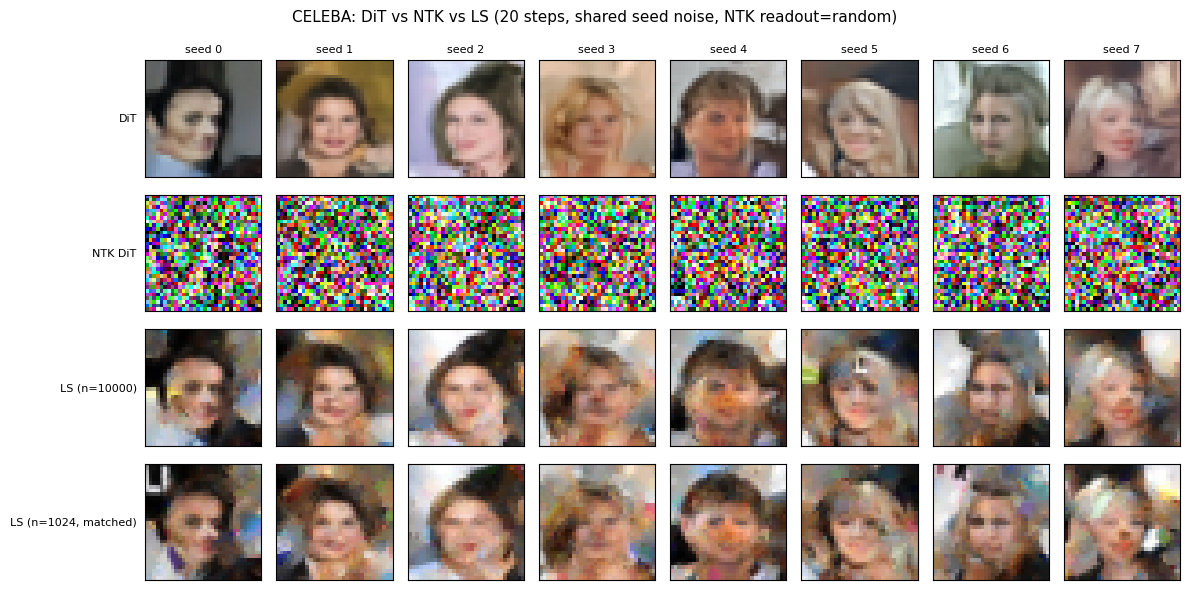

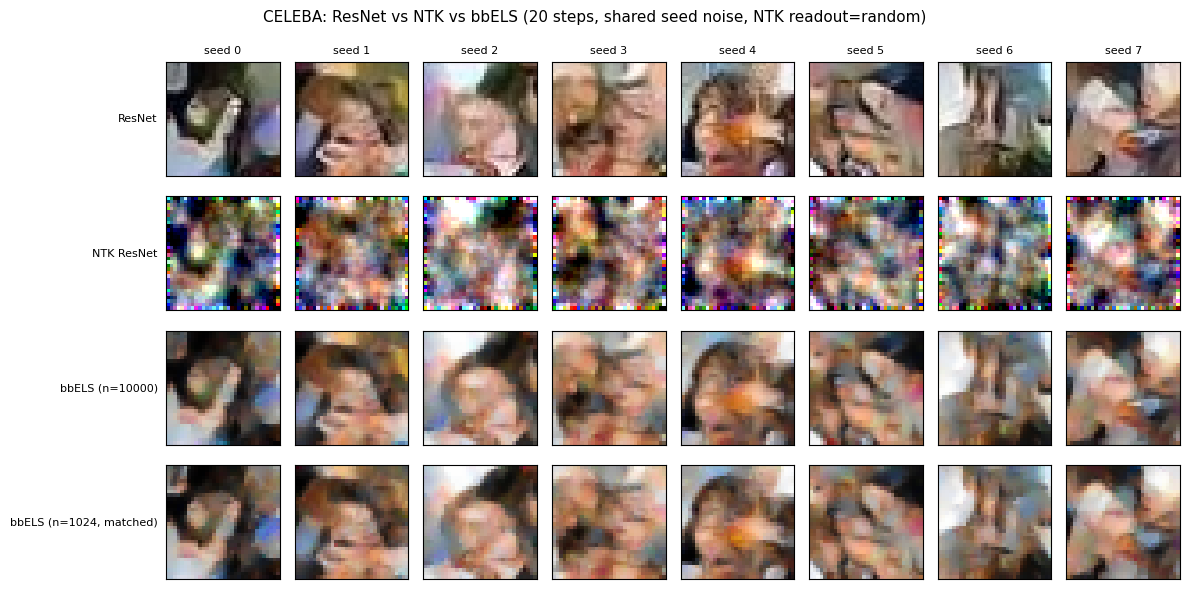

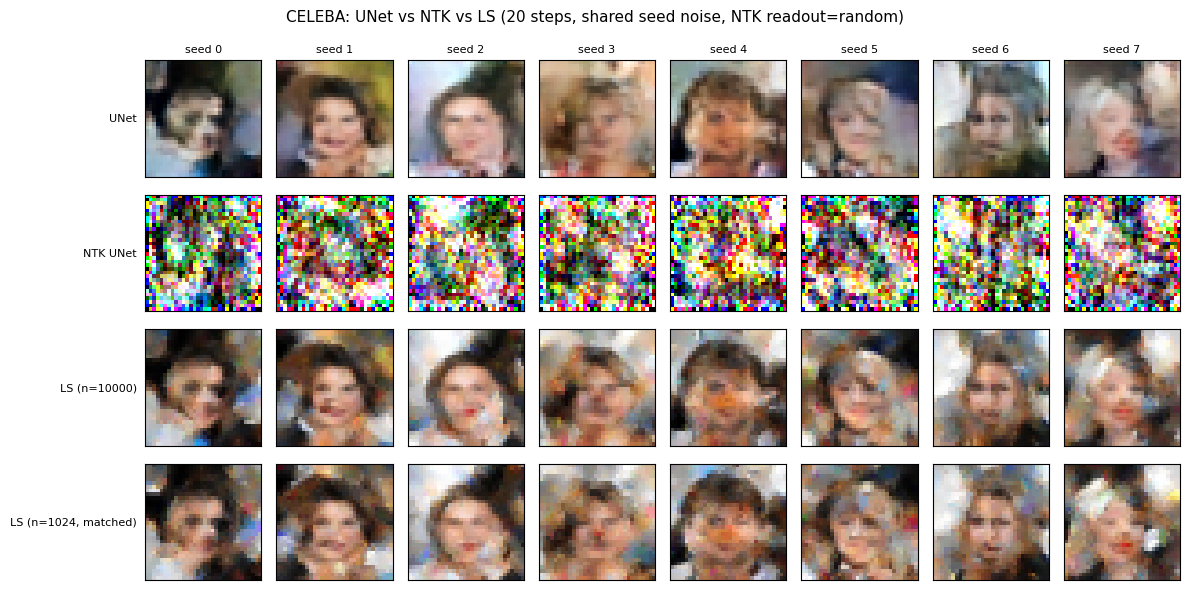

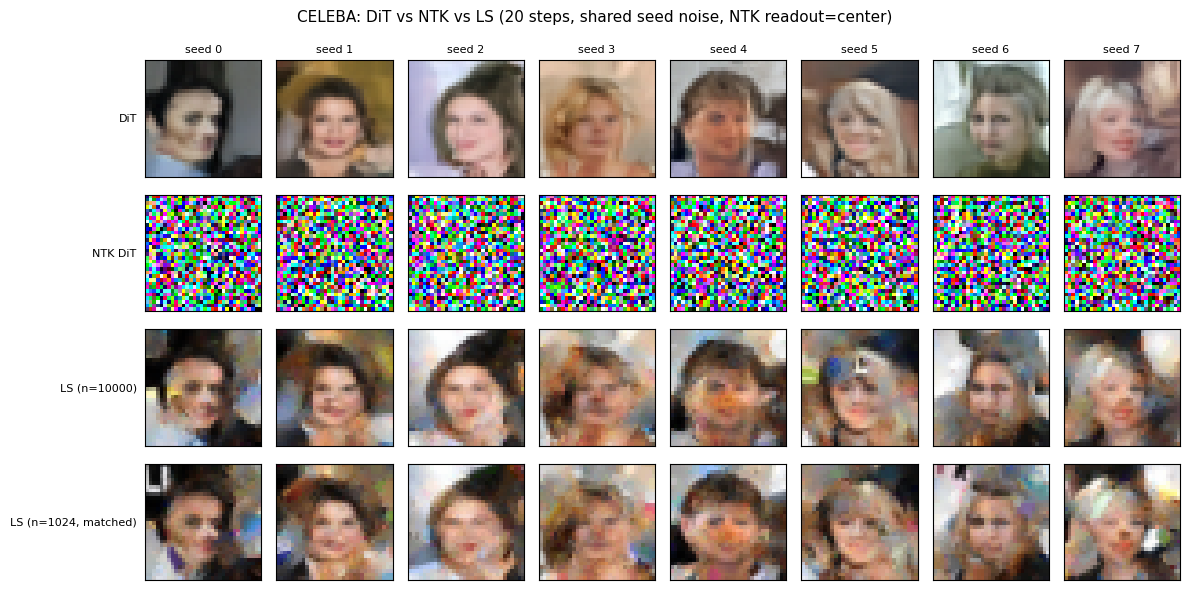

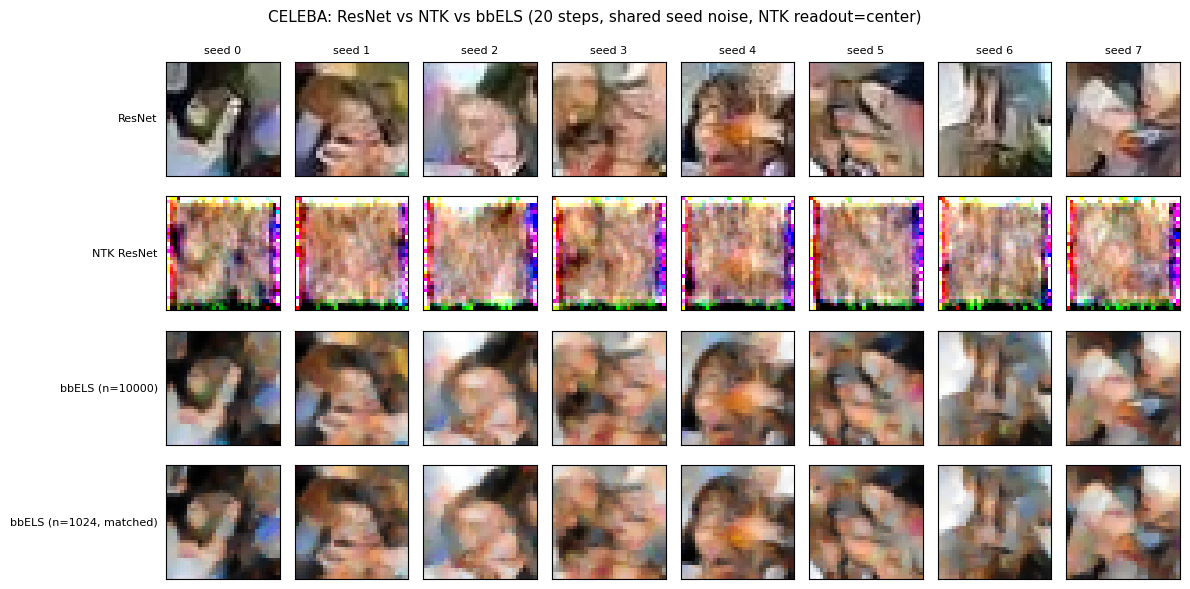

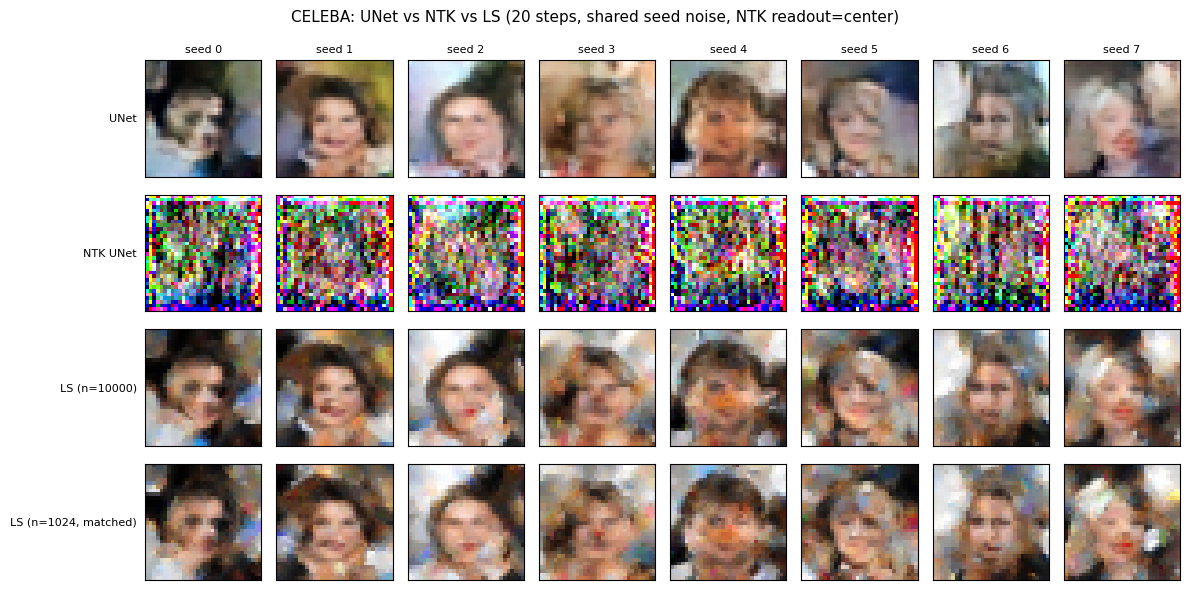

In [4]:
for name, art in artifacts.items():
    plot_sample_grid(art)
    plt.show()

## Pointwise score agreement

The samples answer "do these look alike"; this answers "are these the same function". Every model's $\varepsilon$-prediction is evaluated on **one shared batch** of noised held-out images at each noise level, and the pairwise cosine similarity is plotted against the reverse step.

This is the sharper test of the question: two score functions can produce visually similar samples while disagreeing pointwise, and can agree at high noise (where everything is close to the Gaussian score) while diverging as structure appears.

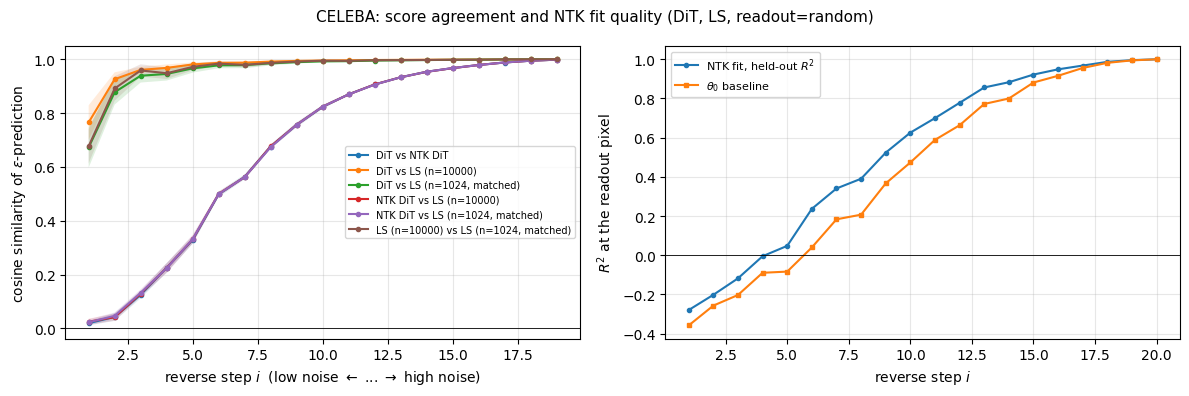

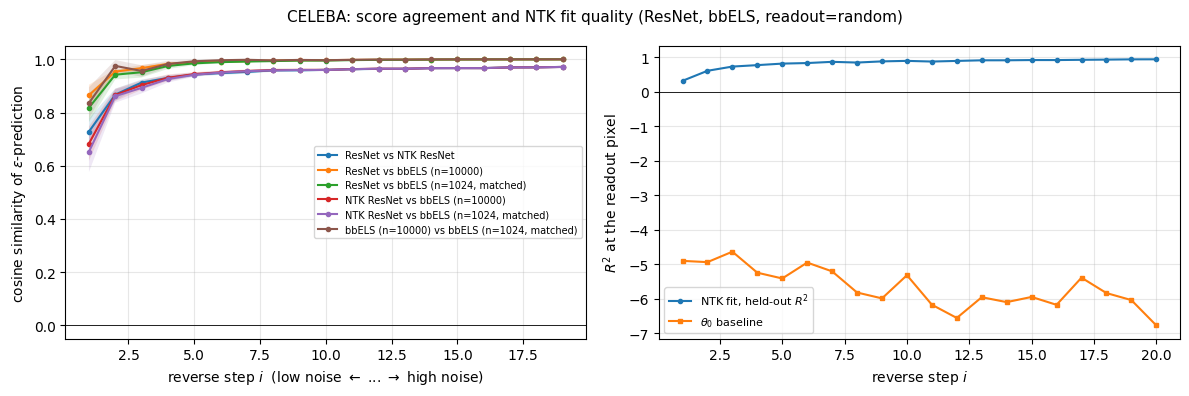

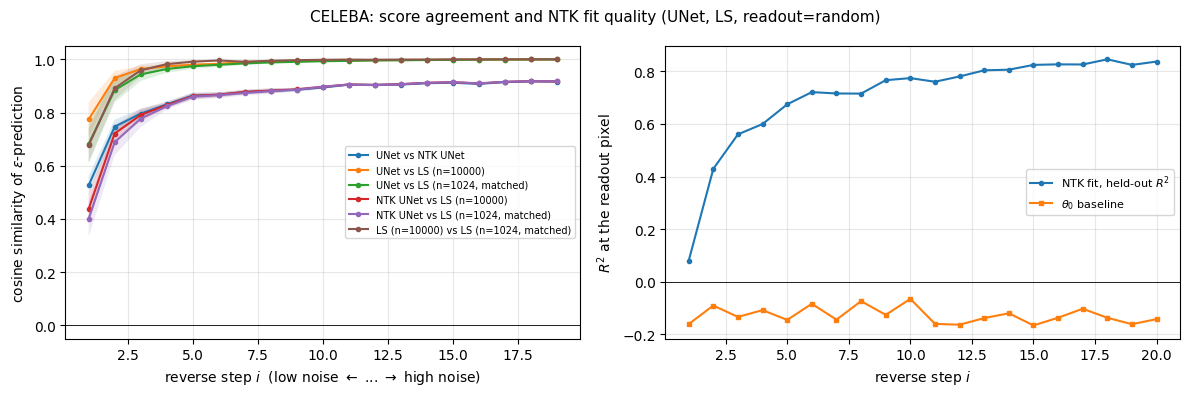

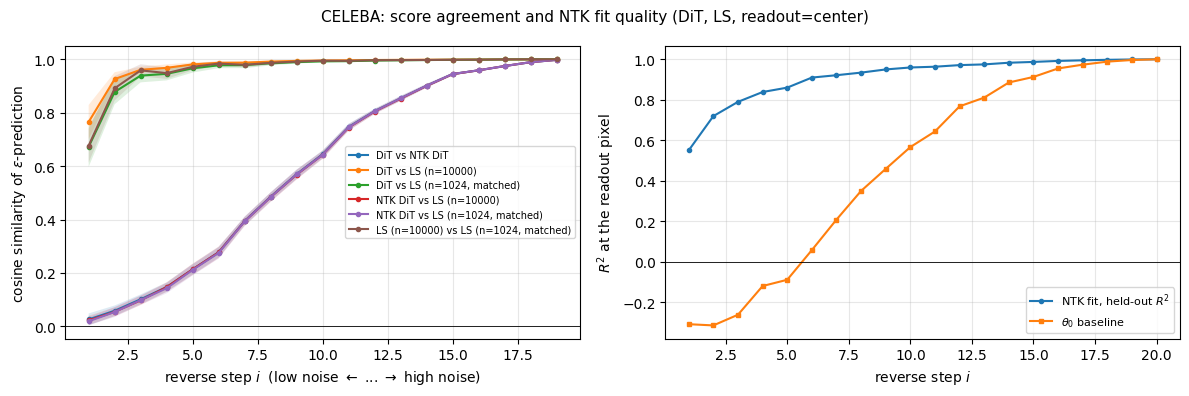

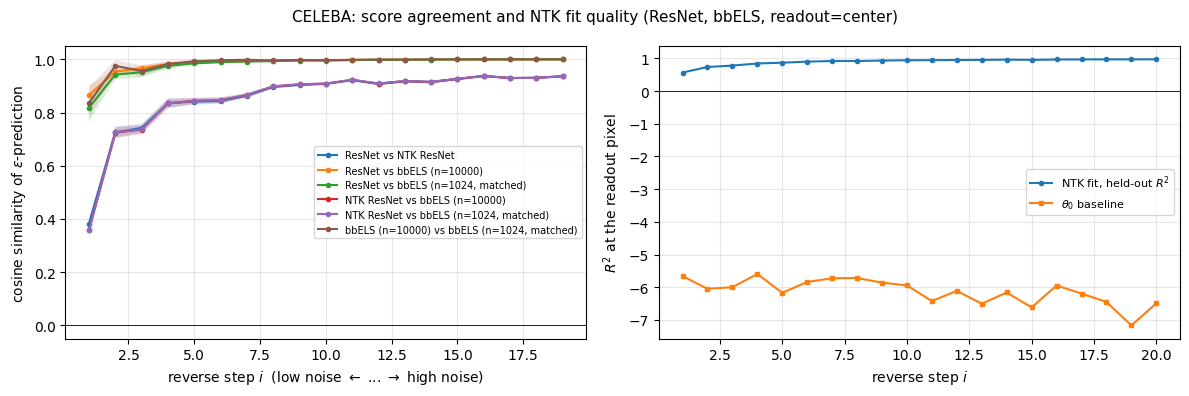

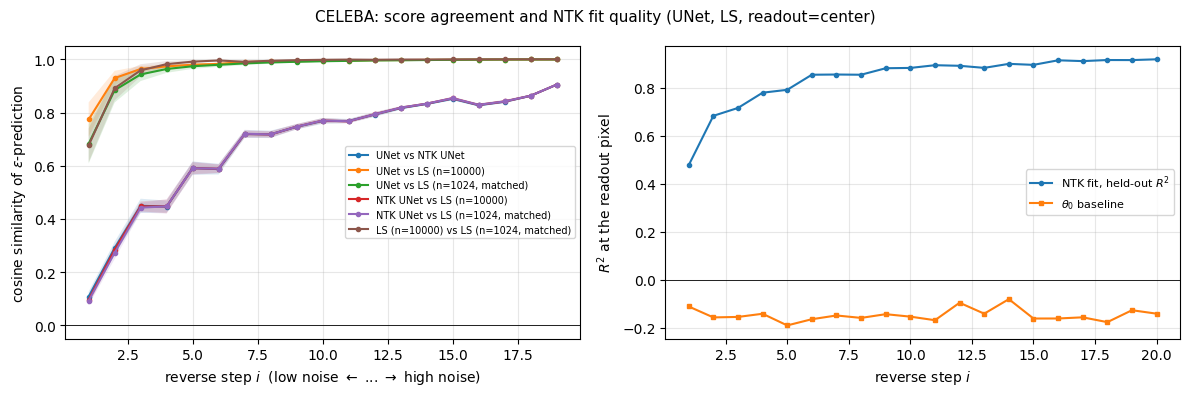

In [5]:
def plot_agreement(art):
    steps = np.asarray(art["agreement_steps"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for pair, vals in art["agreement"].items():
        v = vals.numpy()  # (n_steps, n_images)
        m, s = v.mean(1), v.std(1)
        label = " vs ".join(art["labels"][p] for p in pair.split("|"))
        axes[0].plot(steps, m, marker="o", ms=3, label=label)
        axes[0].fill_between(steps, m - s, m + s, alpha=0.15)

    axes[0].set_xlabel("reverse step $i$  (low noise $\\leftarrow$ ... $\\rightarrow$ high noise)")
    axes[0].set_ylabel("cosine similarity of $\\varepsilon$-prediction")
    axes[0].axhline(0.0, color="k", lw=0.6)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(fontsize=7)

    diag = art["ntk_diagnostics"]
    ds = sorted(diag)
    axes[1].plot(ds, [diag[i]["holdout_r2"] for i in ds], marker="o", ms=3,
                 label="NTK fit, held-out $R^2$")
    axes[1].plot(ds, [diag[i]["holdout_r2_theta0"] for i in ds], marker="s", ms=3,
                 label=r"$\theta_0$ baseline")
    axes[1].axhline(0.0, color="k", lw=0.6)
    axes[1].set_xlabel("reverse step $i$")
    axes[1].set_ylabel("$R^2$ at the readout pixel")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend(fontsize=8)

    name = art["metadata"]["name"].upper()
    fig.suptitle(f"{name}: score agreement and NTK fit quality "
                 f"({art['network_label']}, {art['score_module_type']}, "
                 f"readout={art['_readout']})", fontsize=11)
    fig.tight_layout()
    return fig


for name, art in artifacts.items():
    plot_agreement(art)
    plt.show()

## NTK fit diagnostics

Sanity checks on the regression itself, per noise level:

- `train_r2` &mdash; how well the ridge solution reproduces its own training targets. Near 1 means the kernel system was solved; well below 1 means the ridge is dominating.
- `holdout_r2` &mdash; the number that actually matters. If this sits near 0, the NTK model has not learned a useful denoiser at that noise level and its samples should not be over-interpreted. `holdout_r2_theta0` is the same quantity for the untrained $\theta_0$, as a floor.
- `train_reconstruction_rel` &mdash; end-to-end check that applying $d\theta$ through the JVP actually reproduces the kernel system's own fitted values $\Theta a$ on the training readouts. This is the diagnostic that catches a mismatch between how the gradient rows were flattened and how $d\theta$ is unflattened, and it is also where finite gradient precision shows up: it is largest at the low-noise steps, where the Gram is most ill-conditioned and the ridge coefficients are largest.
- `delta_norm` &mdash; $\lVert d\theta \rVert$. A very large value means the kernel system was ill-conditioned and the fit is extrapolating hard.

In [6]:
for name, art in artifacts.items():
    diag = art["ntk_diagnostics"]
    print(f"=== {name} ===")
    print(f"{'step':>4} {'beta_t':>8} {'train_R2':>9} {'hold_R2':>9} {'R2(th0)':>9} "
          f"{'|dtheta|':>10} {'recon_rel':>10} {'k(local)':>8}")
    for i in sorted(diag):
        d = diag[i]
        k = art["scales"][i] if i < len(art["scales"]) else "-"
        print(f"{i:>4} {d['beta_t']:>8.4f} {d['train_r2']:>9.4f} "
              f"{d.get('holdout_r2', float('nan')):>9.4f} {d.get('holdout_r2_theta0', float('nan')):>9.4f} "
              f"{d['delta_norm']:>10.3e} {d.get('train_reconstruction_rel', float('nan')):>10.2e} {k:>8}")
    print()

=== celeba_DiT_LS_N1024_random ===
step   beta_t  train_R2   hold_R2   R2(th0)   |dtheta|  recon_rel k(local)
   1   0.0061    0.6059   -0.2795   -0.3580  1.581e+00   6.07e-05        3
   2   0.0241    0.2051   -0.2018   -0.2570  3.752e-01   3.74e-05        3
   3   0.0537    0.5975   -0.1179   -0.2028  1.564e+00   4.45e-05        3
   4   0.0940    0.6326   -0.0049   -0.0894  1.596e+00   3.93e-05        5
   5   0.1442    0.6492    0.0480   -0.0834  1.584e+00   5.62e-05        5
   6   0.2031    0.9102    0.2368    0.0398  3.756e+00   2.23e-04        5
   7   0.2691    0.6940    0.3407    0.1834  1.579e+00   5.24e-05        7
   8   0.3408    0.9436    0.3905    0.2072  3.414e+00   1.21e-04        7
   9   0.4162    0.9491    0.5236    0.3667  3.259e+00   7.70e-05        7
  10   0.4938    0.9581    0.6258    0.4735  3.184e+00   1.06e-04        7
  11   0.5714    0.9599    0.6998    0.5888  3.064e+00   1.31e-04        9
  12   0.6474    0.9658    0.7777    0.6635  2.891e+00   1.07e-04